Welcome to the Joe Ryan pitching experience. I love Joe Ryan but he tends to be pretty poor in the second half of the season compared to the first. This analysis only looks at the data in 2026 after a few terrible starts post All-Star Break. I started working on this before we got word of his injury but in light of that it could be illuminating to see what changes when pitchers struggle with different minor injuries. This also includes a fun little 2D pitch simulator from the perspective of home plate. Enjoy!

In [1]:
import os
import certifi

os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()
os.environ["SSL_CERT_FILE"] = certifi.where()

In [2]:
import pybaseball
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

In [3]:
from pybaseball import pitching_stats_bref, pitching_stats_range, statcast, playerid_lookup

pybaseball.cache.enable()
pd.set_option('display.max_columns', None)

In [4]:
# Let's start with getting Joe Ryan's pitching data for the 2026 season so far

pitching_data_2026 = pitching_stats_bref(2026)[pitching_stats_bref(2026)["ERA"] != "NaN"] # This is eliminating the people who didn't actually pitch
joe_ryan_2026 = pitching_data_2026[pitching_data_2026["Name"] == "Joe Ryan"]
print(joe_ryan_2026)

         Name  Age  #days     Lev         Tm   G  GS    W     L  SV     IP  \
679  Joe Ryan   30      3  Maj-AL  Minnesota  26  26  6.0  10.0 NaN  138.2   

       H   R  ER  BB   SO  HR  HBP   ERA   AB  2B  3B  IBB  GDP  SF  SB  CS  \
679  133  72  59  30  151  21   10  3.83  543  29   2    0    4   5  19   4   

     PO   BF   Pit   Str   StL   StS  GB/FB    LD   PU   WHIP  BAbip  SO9  \
679   1  588  2339  0.67  0.17  0.12   0.37  0.23  0.1  1.175  0.298  9.8   

     SO/W   mlbID  
679  5.03  657746  


In [5]:
# Let's get Joe's stats from the start of the season to the All-Star Break
pre_break_stats_2026 = pitching_stats_range("2026-03-26", "2026-07-12")
joe_ryan_pre_break_stats_2026 = pre_break_stats_2026[pre_break_stats_2026["Name"] == "Joe Ryan"]
print(joe_ryan_pre_break_stats_2026)

         Name  Age  #days     Lev         Tm   G  GS    W    L  SV     IP   H  \
585  Joe Ryan   30     73  Maj-AL  Minnesota  20  20  6.0  5.0 NaN  110.1  91   

      R  ER  BB   SO  HR  HBP   ERA   AB  2B  3B  IBB  GDP  SF  SB  CS  PO  \
585  46  35  25  128  10    5  2.85  417  23   0    0    2   3  15   4   1   

      BF   Pit   Str   StL   StS  GB/FB    LD    PU   WHIP  BAbip   SO9  SO/W  \
585  450  1820  0.67  0.17  0.12   0.37  0.24  0.12  1.051  0.287  10.4  5.12   

      mlbID  
585  657746  


In [6]:
# Joe's stats in the few starts he's had since the All-Star Break
post_break_stats_2026 = pitching_stats_range("2026-07-17", "2026-08-10")
joe_ryan_post_break_stats_2026 = post_break_stats_2026[post_break_stats_2026["Name"] == "Joe Ryan"]
print(joe_ryan_post_break_stats_2026)

         Name  Age  #days     Lev         Tm  G  GS   W    L  SV    IP   H  \
426  Joe Ryan   30     49  Maj-AL  Minnesota  3   3 NaN  3.0 NaN  15.1  25   

      R  ER  BB  SO  HR  HBP   ERA  AB  2B  3B  IBB  GDP  SF  SB  CS  PO  BF  \
426  17  16   2  10   7    0  9.39  69   5   1    0    1   2   1   0   0  73   

     Pit   Str   StL   StS  GB/FB    LD    PU   WHIP  BAbip  SO9  SO/W   mlbID  
426  270  0.67  0.15  0.08   0.36  0.25  0.05  1.761  0.333  5.9   5.0  657746  


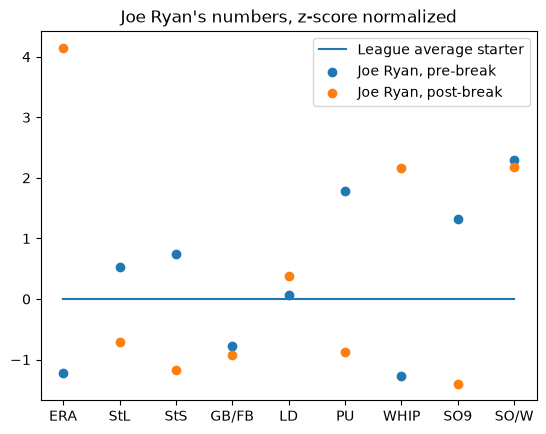

In [7]:
# Gets all of the starting pitchers data (at least 5 games started this year)
starting_pitchers_data = pitching_data_2026[pitching_data_2026["GS"] >= 5]

imp_stat_indices = [15, 28, 29, 30, 31, 32, 33, 35, 36] # indices in starting pitchers data of important pitcher stats
# These correspond to ERA, StL, StS, GB/FB, LD, PU, WHIP, SO9, SO/W

starting_pitchers_averages = starting_pitchers_data.mean(numeric_only=True).iloc[imp_stat_indices]
starting_pitchers_sd = starting_pitchers_data.std(numeric_only=True).iloc[imp_stat_indices]

# Now we're going to z-score normalize all of Ryan's important stats against the starting pitcher stats
ryan_pre_break_imp_stats_2026 = (joe_ryan_pre_break_stats_2026.select_dtypes(include="number").iloc[0, imp_stat_indices])
normalized_ryan_pre_break_stats = (ryan_pre_break_imp_stats_2026 - starting_pitchers_averages) / starting_pitchers_sd
ryan_post_break_imp_stats_2026 = (joe_ryan_post_break_stats_2026.select_dtypes(include="number").iloc[0, imp_stat_indices])
normalized_ryan_post_break_stats = (ryan_post_break_imp_stats_2026 - starting_pitchers_averages) / starting_pitchers_sd

# Now, let's just plot the zeros against Ryan's numbers
plt.title("Joe Ryan's numbers, z-score normalized")
plt.plot(starting_pitchers_averages.index, np.zeros(len(starting_pitchers_averages.index)), label = 'League average starter') 
plt.scatter(starting_pitchers_averages.index, normalized_ryan_pre_break_stats, label = 'Joe Ryan, pre-break')
plt.scatter(starting_pitchers_averages.index, normalized_ryan_post_break_stats, label = 'Joe Ryan, post-break')
plt.legend()
plt.show()

In [8]:
def update_pitch_track(current_pos, current_vel, current_time, acceleration, dt):
    '''
    Updates the actual pitch details, position, velocity, and time

    Inputs:
        current_pos: np array 
        current_vel: np array
        current_time: number
        dt

    Returns:
        next_pos: np array
        next_vel: np array
        next_time: number
    '''

    mid_vel = current_vel + acceleration * (0.5 * dt)

    next_pos = current_pos + mid_vel * dt
    next_vel = current_vel + acceleration * dt
    next_time = current_time + dt
    
    return next_pos, next_vel, next_time

In [9]:
def pitch_simulator(pitch, dt):
    '''
    Returns lists of pitch details tracked through the air - the positions, velocities and times

    Input:
        pitch: pitch data, shape (119,)
    Returns:
        positions, velocities, times: all np arrays
    '''
    positions = []
    velocities = []
    times = []

    # These velocities are for y = 50 down, but the accelerations apply the whole way through
    x_pos = pitch.release_pos_x
    y_pos = pitch.release_pos_y
    z_pos = pitch.release_pos_z
    x_vel = pitch.vx0
    y_vel = pitch.vy0
    z_vel = pitch.vz0
    x_acc = pitch.ax
    y_acc = pitch.ay
    z_acc = pitch.az

    # s = u * t + 1/2 * a * t**2
    # release_pos_y - 50 = y_vel * t + 1/2 * y_acc * t**2
    # 1/2 * y_acc * t**2 + y_vel * t + 50 - release_pos_y = 0
    a = 0.5 * y_acc
    b = y_vel
    c = 50 - y_pos

    time_from_release_to_50 = (-b - np.sqrt(b**2 - 4 * a * c)) / (2 * a)

    initial_x_velocity = x_vel + time_from_release_to_50 * x_acc
    initial_y_velocity = y_vel + time_from_release_to_50 * y_acc
    initial_z_velocity = z_vel + time_from_release_to_50 * z_acc

    avg_acceleration = np.array([x_acc, y_acc, z_acc])

    positions.append(np.array([x_pos, y_pos, z_pos]))
    velocities.append(np.array([initial_x_velocity, initial_y_velocity, initial_z_velocity]))
    times.append(0)

    while positions[-1][1] > 0.708: # 0.708 feet cause Statcast tracks the result of the pitch over the middle of the plate
        next_pos, next_vel, next_time = update_pitch_track(positions[-1], velocities[-1], times[-1], avg_acceleration, dt)
        positions.append(next_pos)
        velocities.append(next_vel)
        times.append(next_time)

    return np.array(positions), np.array(velocities), np.array(times)


In [10]:
def catcher_angle_animation(pitch, dt):

    positions, velocities, times = pitch_simulator(pitch, dt)

    # Let's define the strike zone -> top-left, top-right, bottom-right, bottom-left
    sz_x_values = np.array([-0.71, 0.71, 0.71, -0.71])
    sz_y_values = np.array([pitch.sz_top, pitch.sz_top, pitch.sz_bot, pitch.sz_bot])

    fig, ax = plt.subplots()
    line, = ax.plot([], [], 'o-', lw=2)

    ax.set_xlim(-3, 3)
    ax.set_ylim(0.0, 6.5)
    ax.fill(sz_x_values, sz_y_values, color='lightgray')

    x_values = positions[:, 0]
    z_values = positions[:, 2]

    # 5. Initialization function for clean blitting
    def init():
        line.set_data([], [])
        return line,

    # 6. Update function that adds points sequentially frame-by-frame
    def update(frame):
        # Slice your lists up to the current frame index
        x = x_values[:frame + 1]
        z = z_values[:frame + 1]
        
        # Send the updated series to the line object
        line.set_data(x, z)
        return line,

    # 7. Create the animation using the length of your lists
    ani = FuncAnimation(
        fig, 
        update, 
        frames=len(x_values), 
        init_func=init, 
        blit=True, 
        interval=dt * 1000,    # Time delay between frames in milliseconds (I'm multiplying it so dt can be in seconds)
        repeat=False     # Stop animating once it reaches the last point
    )

    plt.close(fig)
    return HTML(ani.to_jshtml())

In [11]:
def catcher_angle_animation_collection(pitches, dt, sustain_trajectory):

    '''
    pitches: an array of pitches that we're animating on the same plot
    dt: time between frames
    sustain_trajectory: boolean, whether the animation should show keep the entire ball path on screen or not
    '''

    fig, ax = plt.subplots()

    ax.set_xlim(-3, 3)
    ax.set_ylim(0.0, 6.5)

    # Let's define the strike zone -> top-left, top-right, bottom-right, bottom-left
    sz_x_values = np.array([-0.71, 0.71, 0.71, -0.71])

    # Just getting the average strikezone values for the pitches in question here
    sz_tops, sz_bots = [], []
    for pitch in pitches:
        sz_tops.append(pitch["sz_top"])
        sz_bots.append(pitch["sz_bot"])
    sz_top = np.average(sz_tops)
    sz_bot = np.average(sz_bots)
    sz_y_values = np.array([sz_top, sz_top, sz_bot, sz_bot])

    ax.fill(sz_x_values, sz_y_values, color='lightgray')

    x_values = [None] * len(pitches)
    z_values = [None] * len(pitches)

    possible_colors = ["crimson", "royalblue", "gold", "lime", "cyan", "magenta", "orange", "purple", "teal", "forestgreen", "chocolate", "deeppink", "lavender", "skyblue", "salmon"]

    # 5. Initialization function for clean blitting
    lines = []

    for i in range(len(pitches)):
        line, = ax.plot([], [], 'o-', lw = 1.5, color = possible_colors[i], label = {pitches[i]["pitch_name"]})
        lines.append(line) 

    def init():
        for line in lines:
            line.set_data([], [])
        return lines

    # 6. Update function that adds points sequentially frame-by-frame
    def update(frame):
        for i in range(len(pitches)):
            # Slice your lists up to the current frame index
            index = min(frame, len(x_values[i]) - 1)
            x_frame_values = x_values[i][:index + 1] if sustain_trajectory else [x_values[i][index]]
            z_frame_values = z_values[i][:index + 1] if sustain_trajectory else [z_values[i][index]]
            lines[i].set_data(x_frame_values, z_frame_values)
        ax.legend()
        return lines

    for i in range(len(pitches)):
        pitch = pitches[i]
        positions, velocities, times = pitch_simulator(pitch, dt)

        x_values[i] = positions[:, 0]
        z_values[i] = positions[:, 2]

    frame_count = max(len(x_values[i]) for i in range(len(x_values)))

    # 7. Create the animation using the length of your lists
    ani = FuncAnimation(
        fig, 
        update, 
        frames=frame_count, 
        init_func=init, 
        blit=True, 
        interval=dt * 1000,    # Time delay between frames in milliseconds (I'm multiplying it so dt can be in seconds)
        repeat=False           # Stop animating once it reaches the last point
    )

    plt.close(fig)
    return HTML(ani.to_jshtml())

In [12]:
pitch_data = statcast()

start_dt 2026-09-21
end_dt 2026-09-22
This is a large query, it may take a moment to complete


100%|██████████| 2/2 [00:00<00:00,  6.17it/s]


In [13]:
def get_pitch_details(pitch, average_pitch = False):
    print("Pitching arm: ", pitch.p_throws)
    print("Pitch name: ", pitch.pitch_name)
    print("Zone: ", int(pitch.zone))
    print("Horizontal run: ", pitch.pfx_x)
    print("Vertical run: ", pitch.pfx_z)
    print("Plate x: ", pitch.plate_x)
    print("Plate z: ", pitch.plate_z)
    return catcher_angle_animation(pitch, dt = 0.005)

In [14]:
twins_pre_break_pitch_data = statcast(start_dt = "2026-03-25", end_dt = "2026-07-13", team = "MIN")
twins_post_break_pitch_data = statcast(start_dt = "2026-07-17", end_dt = "2026-08-10", team = "MIN")
ryan_id = playerid_lookup("Ryan", "Joe").key_mlbam.astype("Int64")

This is a large query, it may take a moment to complete


100%|██████████| 111/111 [00:12<00:00,  8.96it/s]

This is a large query, it may take a moment to complete



100%|██████████| 25/25 [00:04<00:00,  5.90it/s]


Gathering player lookup table. This may take a moment.


In [15]:
ryan_pre_break_pitch_data = twins_pre_break_pitch_data[twins_pre_break_pitch_data["pitcher"] == ryan_id.iloc[0]]
ryan_post_break_pitch_data = twins_post_break_pitch_data[twins_post_break_pitch_data["pitcher"] == ryan_id.iloc[0]]

# Ryan throws 6 pitches
ryan_pre_break_FF = ryan_pre_break_pitch_data[ryan_pre_break_pitch_data["pitch_name"] == "4-Seam Fastball"]
ryan_pre_break_FT = ryan_pre_break_pitch_data[ryan_pre_break_pitch_data["pitch_name"] == "Sinker"]
ryan_pre_break_SL = ryan_pre_break_pitch_data[ryan_pre_break_pitch_data["pitch_name"] == "Slider"]
ryan_pre_break_ST = ryan_pre_break_pitch_data[ryan_pre_break_pitch_data["pitch_name"] == "Sweeper"]
ryan_pre_break_KC = ryan_pre_break_pitch_data[ryan_pre_break_pitch_data["pitch_name"] == "Knuckle Curve"]
ryan_pre_break_FS = ryan_pre_break_pitch_data[ryan_pre_break_pitch_data["pitch_name"] == "Split-Finger"]

FF_pre_break_ratio = len(ryan_pre_break_FF) / len(ryan_pre_break_pitch_data)
FT_pre_break_ratio = len(ryan_pre_break_FT) / len(ryan_pre_break_pitch_data)
SL_pre_break_ratio = len(ryan_pre_break_SL) / len(ryan_pre_break_pitch_data)
ST_pre_break_ratio = len(ryan_pre_break_ST) / len(ryan_pre_break_pitch_data)
KC_pre_break_ratio = len(ryan_pre_break_KC) / len(ryan_pre_break_pitch_data)
FS_pre_break_ratio = len(ryan_pre_break_FS) / len(ryan_pre_break_pitch_data)

ryan_post_break_FF = ryan_post_break_pitch_data[ryan_post_break_pitch_data["pitch_name"] == "4-Seam Fastball"]
ryan_post_break_FT = ryan_post_break_pitch_data[ryan_post_break_pitch_data["pitch_name"] == "Sinker"]
ryan_post_break_SL = ryan_post_break_pitch_data[ryan_post_break_pitch_data["pitch_name"] == "Slider"]
ryan_post_break_ST = ryan_post_break_pitch_data[ryan_post_break_pitch_data["pitch_name"] == "Sweeper"]
ryan_post_break_KC = ryan_post_break_pitch_data[ryan_post_break_pitch_data["pitch_name"] == "Knuckle Curve"]
ryan_post_break_FS = ryan_post_break_pitch_data[ryan_post_break_pitch_data["pitch_name"] == "Split-Finger"]

FF_post_break_ratio = len(ryan_post_break_FF) / len(ryan_post_break_pitch_data)
FT_post_break_ratio = len(ryan_post_break_FT) / len(ryan_post_break_pitch_data)
SL_post_break_ratio = len(ryan_post_break_SL) / len(ryan_post_break_pitch_data)
ST_post_break_ratio = len(ryan_post_break_ST) / len(ryan_post_break_pitch_data)
KC_post_break_ratio = len(ryan_post_break_KC) / len(ryan_post_break_pitch_data)
FS_post_break_ratio = len(ryan_post_break_FS) / len(ryan_post_break_pitch_data)

In [16]:
sample_ryan_pitch = ryan_pre_break_FF.iloc[0]

ryan_pre_break_average_FF = ryan_pre_break_FF.mean(numeric_only=True)
ryan_pre_break_average_FF['p_throws'] = sample_ryan_pitch['p_throws']
ryan_pre_break_average_FF['pitch_name'] = "4-Seam Fastball"

ryan_pre_break_average_FT = ryan_pre_break_FT.mean(numeric_only=True)
ryan_pre_break_average_FT['p_throws'] = sample_ryan_pitch['p_throws']
ryan_pre_break_average_FT['pitch_name'] = "Sinker"

ryan_pre_break_average_SL = ryan_pre_break_SL.mean(numeric_only=True)
ryan_pre_break_average_SL['p_throws'] = sample_ryan_pitch['p_throws']
ryan_pre_break_average_SL['pitch_name'] = "Slider"

ryan_pre_break_average_ST = ryan_pre_break_ST.mean(numeric_only=True)
ryan_pre_break_average_ST['p_throws'] = sample_ryan_pitch['p_throws']
ryan_pre_break_average_ST['pitch_name'] = "Sweeper"

ryan_pre_break_average_KC = ryan_pre_break_KC.mean(numeric_only=True)
ryan_pre_break_average_KC['p_throws'] = sample_ryan_pitch['p_throws']
ryan_pre_break_average_KC['pitch_name'] = "Knuckle Curve"

ryan_pre_break_average_FS = ryan_pre_break_FS.mean(numeric_only=True)
ryan_pre_break_average_FS['p_throws'] = sample_ryan_pitch['p_throws']
ryan_pre_break_average_FS['pitch_name'] = "Splitter"

ryan_post_break_average_FF = ryan_post_break_FF.mean(numeric_only=True)
ryan_post_break_average_FF['p_throws'] = sample_ryan_pitch['p_throws']
ryan_post_break_average_FF['pitch_name'] = "4-Seam Fastball"

ryan_post_break_average_FT = ryan_post_break_FT.mean(numeric_only=True)
ryan_post_break_average_FT['p_throws'] = sample_ryan_pitch['p_throws']
ryan_post_break_average_FT['pitch_name'] = "Sinker"

ryan_post_break_average_SL = ryan_post_break_SL.mean(numeric_only=True)
ryan_post_break_average_SL['p_throws'] = sample_ryan_pitch['p_throws']
ryan_post_break_average_SL['pitch_name'] = "Slider"

ryan_post_break_average_ST = ryan_post_break_ST.mean(numeric_only=True)
ryan_post_break_average_ST['p_throws'] = sample_ryan_pitch['p_throws']
ryan_post_break_average_ST['pitch_name'] = "Sweeper"

ryan_post_break_average_KC = ryan_post_break_KC.mean(numeric_only=True)
ryan_post_break_average_KC['p_throws'] = sample_ryan_pitch['p_throws']
ryan_post_break_average_KC['pitch_name'] = "Knuckle Curve"

ryan_post_break_average_FS = ryan_post_break_FS.mean(numeric_only=True)
ryan_post_break_average_FS['p_throws'] = sample_ryan_pitch['p_throws']
ryan_post_break_average_FS['pitch_name'] = "Splitter"

In [17]:
# Pre-break
catcher_angle_animation_collection([ryan_pre_break_average_FF, ryan_pre_break_average_FT, ryan_pre_break_average_SL, ryan_pre_break_average_ST, ryan_pre_break_average_KC, ryan_pre_break_average_FS], dt = 0.005, sustain_trajectory=False)

In [18]:
# Post-break
catcher_angle_animation_collection([ryan_post_break_average_FF, ryan_post_break_average_FT, ryan_post_break_average_SL, ryan_post_break_average_ST, ryan_post_break_average_KC, ryan_post_break_average_FS], dt = 0.005, sustain_trajectory=False)

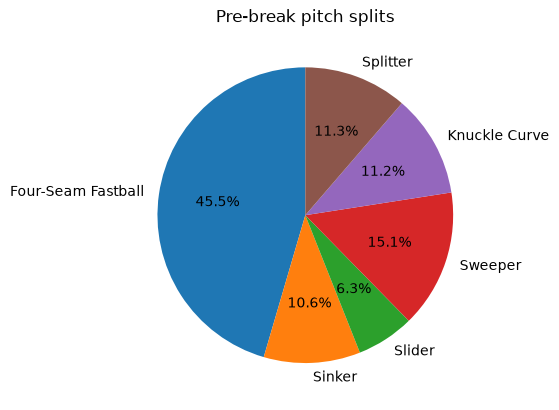

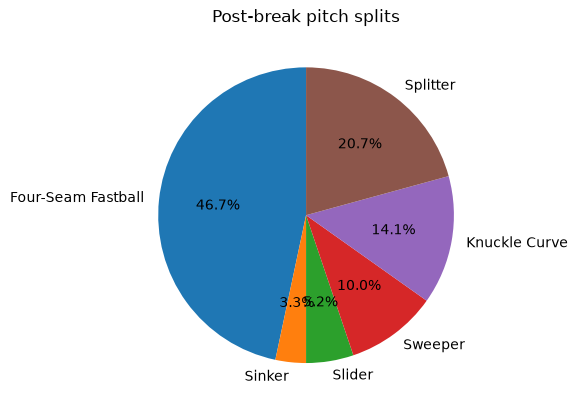

In [33]:
# Comparing his splits

pre_break_pie = np.array([FF_pre_break_ratio, FT_pre_break_ratio, SL_pre_break_ratio, ST_pre_break_ratio, KC_pre_break_ratio, FS_pre_break_ratio])
pre_break_labels = np.array(["Four-Seam Fastball", "Sinker", "Slider", "Sweeper", "Knuckle Curve", "Splitter"])
plt.pie(pre_break_pie, labels = pre_break_labels, autopct = "%1.1f%%", startangle = 90)
plt.title('Pre-break pitch splits')
plt.show()

post_break_pie = np.array([FF_post_break_ratio, FT_post_break_ratio, SL_post_break_ratio, ST_post_break_ratio, KC_post_break_ratio, FS_post_break_ratio])
post_break_labels = np.array(["Four-Seam Fastball", "Sinker", "Slider", "Sweeper", "Knuckle Curve", "Splitter"])
plt.pie(post_break_pie, labels = post_break_labels, autopct = "%1.1f%%", startangle = 90)
plt.title('Post-break pitch splits')
plt.show()